# Previsão do consumo energético de edificações com SVR e Redes Neurais

## Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, SVC
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

## 1. Carregamento dos dados

In [2]:
dados = pd.read_excel("ENB2012_data.xlsx")

dados.columns = [
    "compacidade_relativa",   # X1
    "area_superficie",        # X2
    "area_parede",            # X3
    "area_telhado",           # X4
    "altura_total",           # X5
    "orientacao",             # X6
    "area_janelas",           # X7
    "distribuicao_janelas",   # X8
    "carga_aquecimento",      # Y1 (alvo)
    "carga_resfriamento",     # Y2
]

dados.head()

,compacidade_relativa,area_superficie,area_parede,area_telhado,altura_total,orientacao,area_janelas,distribuicao_janelas,carga_aquecimento,carga_resfriamento
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 2. Análise exploratória

In [3]:
print("Linhas e colunas:", dados.shape)
dados.describe()

Linhas e colunas: (768, 10)


,compacidade_relativa,area_superficie,area_parede,area_telhado,altura_total,orientacao,area_janelas,distribuicao_janelas,carga_aquecimento,carga_resfriamento
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


In [4]:
print("Valores ausentes:", dados.isnull().sum().sum())
print("Linhas duplicadas:", dados.duplicated().sum())

Valores ausentes: 0
Linhas duplicadas: 0


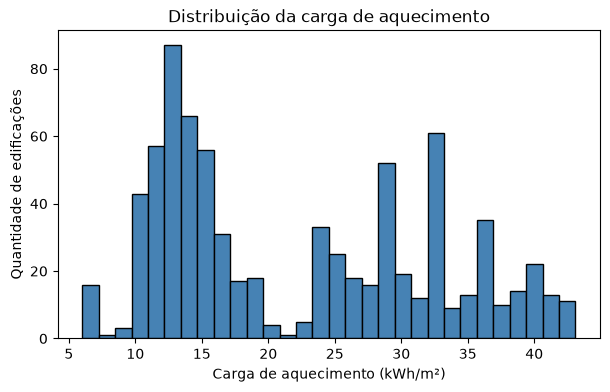

In [5]:
plt.figure(figsize=(7, 4))
plt.hist(dados["carga_aquecimento"], bins=30, color="steelblue", edgecolor="black")
plt.title("Distribuição da carga de aquecimento")
plt.xlabel("Carga de aquecimento (kWh/m²)")
plt.ylabel("Quantidade de edificações")
plt.show()

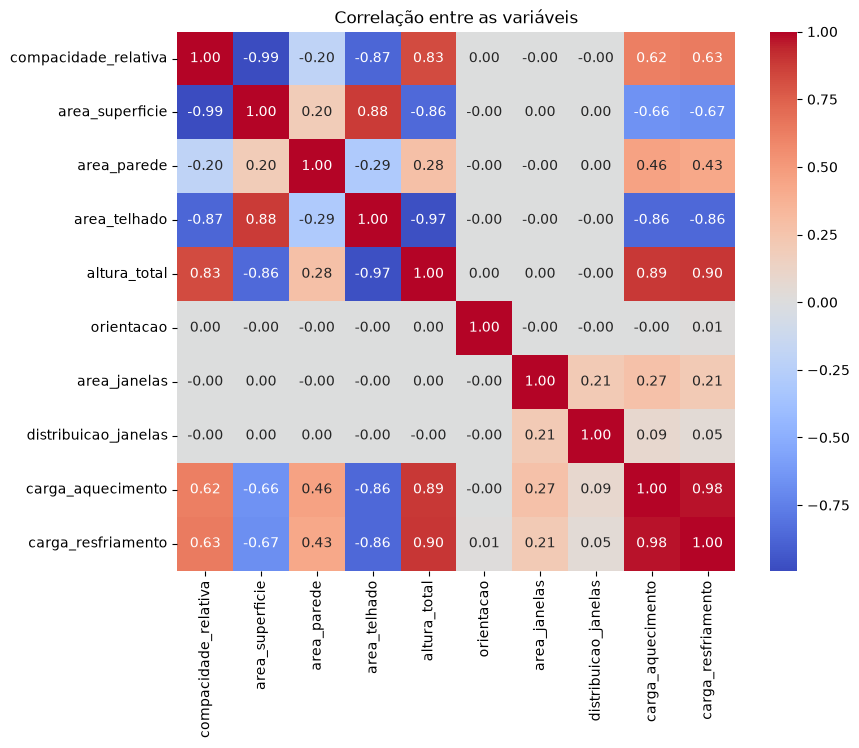

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(dados.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlação entre as variáveis")
plt.show()

## 3. Pré-processamento

In [7]:
X = dados.drop(columns=["carga_aquecimento", "carga_resfriamento"])
y = dados["carga_aquecimento"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)   # ajusta só no treino
X_teste_pad = scaler.transform(X_teste)         # aplica no teste

print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 614 | Teste: 154


In [8]:
def avaliar_regressao(nome, y_real, y_previsto):
    mae = mean_absolute_error(y_real, y_previsto)
    mse = mean_squared_error(y_real, y_previsto)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_previsto)
    print(f"{nome}: MAE = {mae:.2f} | MSE = {mse:.2f} | RMSE = {rmse:.2f} | R² = {r2:.3f}")
    return {"Modelo": nome, "MAE": mae, "MSE": mse, "RMSE": rmse, "R²": r2}

In [9]:
# baseline: sempre prevê a média do treino
previsao_media = np.full(len(y_teste), y_treino.mean())
resultado_baseline = avaliar_regressao("Baseline (média)", y_teste, previsao_media)

Baseline (média): MAE = 9.27 | MSE = 104.81 | RMSE = 10.24 | R² = -0.006


## 4. SVM para regressão (SVR)

In [10]:
# teste: sem e com padronização
svr_sem_pad = SVR(kernel="rbf")
svr_sem_pad.fit(X_treino, y_treino)
avaliar_regressao("SVR sem padronização", y_teste, svr_sem_pad.predict(X_teste))

svr_com_pad = SVR(kernel="rbf")
svr_com_pad.fit(X_treino_pad, y_treino)
avaliar_regressao("SVR com padronização", y_teste, svr_com_pad.predict(X_teste_pad));

SVR sem padronização: MAE = 4.23 | MSE = 31.97 | RMSE = 5.65 | R² = 0.693


SVR com padronização: MAE = 1.89 | MSE = 7.97 | RMSE = 2.82 | R² = 0.924


In [11]:
parametros = {
    "C": [1, 10, 100, 1000],
    "epsilon": [0.1, 0.5, 1],
    "gamma": ["scale", 0.1, 0.01],
}

busca = GridSearchCV(SVR(kernel="rbf"), parametros, cv=5, scoring="neg_mean_absolute_error")
busca.fit(X_treino_pad, y_treino)

print("Melhores parâmetros:", busca.best_params_)

Melhores parâmetros: {'C': 1000, 'epsilon': 0.1, 'gamma': 0.1}


In [12]:
svr = busca.best_estimator_
y_previsto_svr = svr.predict(X_teste_pad)
resultado_svr = avaliar_regressao("SVR (ajustado)", y_teste, y_previsto_svr)

SVR (ajustado): MAE = 0.34 | MSE = 0.22 | RMSE = 0.47 | R² = 0.998


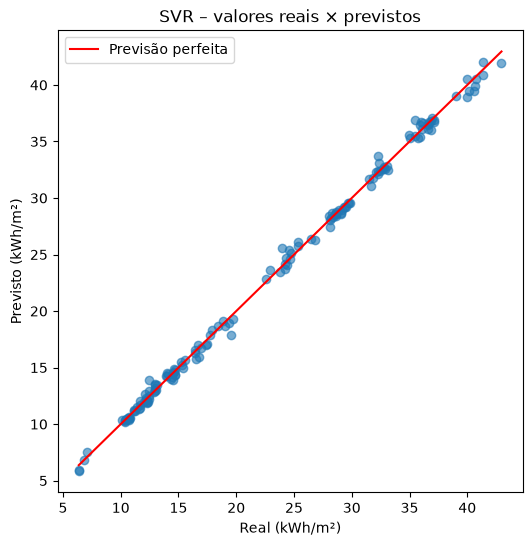

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_teste, y_previsto_svr, alpha=0.6)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], color="red", label="Previsão perfeita")
plt.title("SVR – valores reais × previstos")
plt.xlabel("Real (kWh/m²)")
plt.ylabel("Previsto (kWh/m²)")
plt.legend()
plt.show()

## 5. SVM para classificação (SVC)

In [14]:
# divide a carga de aquecimento em 3 faixas pelos tercis
y_classe = pd.qcut(y, q=3, labels=["Baixo", "Médio", "Alto"])
print("Limites das faixas (kWh/m²):", y.quantile([1/3, 2/3]).round(2).tolist())

yc_treino, yc_teste = train_test_split(y_classe, test_size=0.2, random_state=42)

Limites das faixas (kWh/m²): [14.54, 28.63]


In [15]:
svc = SVC(kernel="rbf", C=10)
svc.fit(X_treino_pad, yc_treino)
yc_previsto = svc.predict(X_teste_pad)

print("Acurácia:", round(accuracy_score(yc_teste, yc_previsto), 3))
print(classification_report(yc_teste, yc_previsto))

Acurácia: 0.909
              precision    recall  f1-score   support

        Alto       0.96      0.91      0.94        56
       Baixo       0.91      0.96      0.93        50
       Médio       0.85      0.85      0.85        48

    accuracy                           0.91       154
   macro avg       0.91      0.91      0.91       154
weighted avg       0.91      0.91      0.91       154



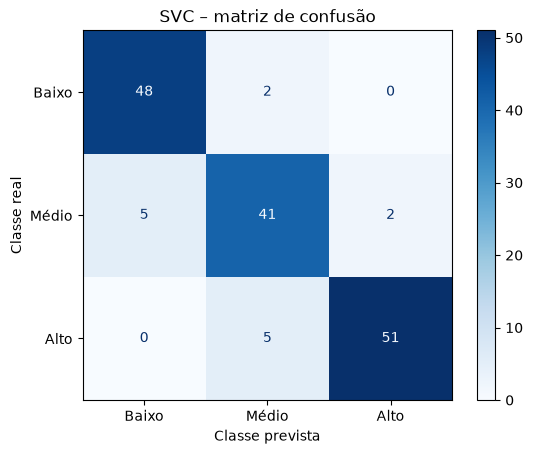

In [16]:
matriz = confusion_matrix(yc_teste, yc_previsto, labels=["Baixo", "Médio", "Alto"])
ConfusionMatrixDisplay(matriz, display_labels=["Baixo", "Médio", "Alto"]).plot(cmap="Blues")
plt.title("SVC – matriz de confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

## 6. Rede Neural (MLP)

In [17]:
mlp = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)
mlp.fit(X_treino_pad, y_treino)

y_previsto_mlp = mlp.predict(X_teste_pad)
resultado_mlp = avaliar_regressao("Rede Neural (MLP)", y_teste, y_previsto_mlp)

Rede Neural (MLP): MAE = 0.45 | MSE = 0.39 | RMSE = 0.62 | R² = 0.996


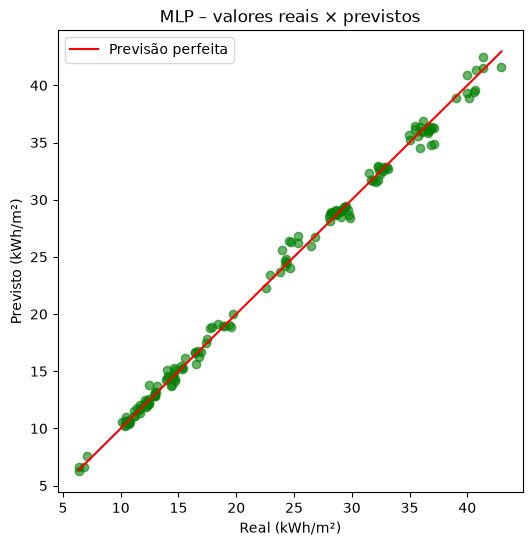

In [18]:
plt.figure(figsize=(6, 6))
plt.scatter(y_teste, y_previsto_mlp, alpha=0.6, color="green")
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], color="red", label="Previsão perfeita")
plt.title("MLP – valores reais × previstos")
plt.xlabel("Real (kWh/m²)")
plt.ylabel("Previsto (kWh/m²)")
plt.legend()
plt.show()

## 7. Comparação dos modelos

In [19]:
tabela = pd.DataFrame([resultado_baseline, resultado_svr, resultado_mlp])
tabela.round(3)

,Modelo,MAE,MSE,RMSE,R²
0,Baseline (média),9.272,104.808,10.238,-0.006
1,SVR (ajustado),0.342,0.217,0.466,0.998
2,Rede Neural (MLP),0.447,0.387,0.622,0.996


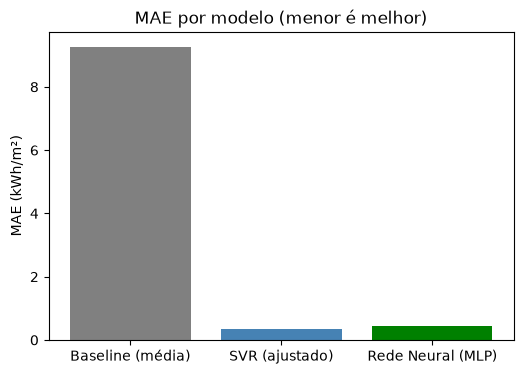

In [20]:
plt.figure(figsize=(6, 4))
plt.bar(tabela["Modelo"], tabela["MAE"], color=["gray", "steelblue", "green"])
plt.title("MAE por modelo (menor é melhor)")
plt.ylabel("MAE (kWh/m²)")
plt.show()

In [21]:
exemplos = pd.DataFrame({
    "Real": y_teste.values[:10],
    "SVR": y_previsto_svr[:10].round(2),
    "MLP": y_previsto_mlp[:10].round(2),
    "Faixa real": yc_teste.values[:10],
    "Faixa prevista (SVC)": yc_previsto[:10],
})
exemplos

,Real,SVR,MLP,Faixa real,Faixa prevista (SVC)
0,16.47,16.28,16.65,Médio,Médio
1,13.17,13.44,13.67,Baixo,Baixo
2,32.82,32.72,32.85,Alto,Alto
3,41.32,41.99,41.50,Alto,Alto
4,16.69,16.97,16.81,Médio,Médio
5,23.80,23.48,23.68,Médio,Médio
6,24.31,24.70,24.80,Médio,Médio
7,28.67,28.60,28.66,Alto,Médio
8,19.52,17.91,18.85,Médio,Médio
9,28.07,28.38,28.49,Médio,Alto
